### Clone GitHub Repository

Use the cell below to clone your repository. Replace `YOUR_REPOSITORY_URL` with the URL of your GitHub repository.

*Note: If your repository is private, you will need to include your GitHub personal access token (PAT) in the URL: `https://<TOKEN>@github.com/username/repo.git`.*

In [4]:
# Replace these variables with your GitHub username and repository name
GITHUB_USERNAME = 'nmet0002'
REPO_NAME = 'NathanMetcalfe_MMA3001_Project'

# Retrieve your GitHub PAT from Colab Secrets securely
from google.colab import userdata
try:
    GITHUB_PAT = userdata.get('GH_PAT')
    # Construct the authenticated URL
    REPO_URL = f'https://{GITHUB_PAT}@github.com/{GITHUB_USERNAME}/{REPO_NAME}.git'
    print("Successfully retrieved GITHUB_PAT from secrets.")
except Exception as e:
    print("Error retrieving GITHUB_PAT from secrets. Please ensure GITHUB_PAT is set in Colab Secrets.")
    REPO_URL = f'https://github.com/{GITHUB_USERNAME}/{REPO_NAME}.git'

# Clone the repository
!git clone {REPO_URL}

# Automatically append the cloned repository to the system path
import os
import sys

repo_path = os.path.abspath(REPO_NAME)
if os.path.exists(repo_path):
    if repo_path not in sys.path:
        sys.path.append(repo_path)
        print(f"Added {repo_path} to system path.")
    else:
        print(f"{repo_path} is already in system path.")
else:
    print(f"Could not find cloned directory at {repo_path}. Please check if the clone was successful.")

Successfully retrieved GITHUB_PAT from secrets.
fatal: destination path 'NathanMetcalfe_MMA3001_Project' already exists and is not an empty directory.
/content/NathanMetcalfe_MMA3001_Project is already in system path.


### Switch to a Different Branch

Run the cell below to inspect the available branches in your repository and check out a different branch.

In [5]:
# Change your working directory to the cloned repository
%cd /content/NathanMetcalfe_MMA3001_Project

print("--- Current Status & Available Branches ---")
# Fetch latest remote branch information
!git fetch --all
# List all local and remote branches
!git branch -a

# --- Change this to the branch you wish to switch to ---
TARGET_BRANCH = '2---Fitting'

print(f"\n--- Switching to {TARGET_BRANCH} ---")
!git checkout {TARGET_BRANCH}

# Go back to the main content directory
%cd /content

/content/NathanMetcalfe_MMA3001_Project
--- Current Status & Available Branches ---
* 2---Fitting
  main
  remotes/origin/1---Exploration
  remotes/origin/2-----Fitting
  remotes/origin/2---Fitting
  remotes/origin/HEAD -> origin/main
  remotes/origin/main

--- Switching to 2---Fitting ---
Already on '2---Fitting'
Your branch is up to date with 'origin/2---Fitting'.
/content


In [6]:
# Import the functions from the 'Functions' subdirectory inside your repository
from Functions import mill_analysis_funcs as mf

In [7]:
#import MAT file from drive and clean up with my function

#Allow access to google drive, where file is stored
from google.colab import drive
drive.mount('/content/drive')

import scipy.io

# Define the path to the .mat file
file_path = '/content/drive/MyDrive/MMA3001/mill.mat'

# Load the .mat file
mat_data = scipy.io.loadmat(file_path)

df_mill_filtered = mf.convert_data(mat_data)


Mounted at /content/drive


In [12]:
# Display the first few rows of the cleaned DataFrame to verify the import
display(df_mill_filtered.head())
df_mill_filtered.info()

,case,run,VB,time,DOC,feed,material,smcAC,smcDC,vib_table,vib_spindle,AE_table,AE_spindle
0,1,1,0.00,2,1.5,0.5,1,"[-0.01708984375, 0.263671875, 0.20751953125, 0...","[0.625, 0.810546875, 0.78125, 0.849609375, 1.0...","[0.078125, 0.08544921875, 0.078125, 0.07324218...","[0.31494140625, 0.301513671875, 0.303955078125...","[0.0872802734375, 0.0982666015625, 0.092163085...","[0.103759765625, 0.123291015625, 0.10498046875..."
3,1,4,0.11,7,1.5,0.5,1,"[0.1123046875, 0.009765625, -0.1513671875, -0....","[0.1318359375, 0.3955078125, 0.7568359375, 0.8...","[0.0830078125, 0.07568359375, 0.06591796875, 0...","[0.316162109375, 0.311279296875, 0.302734375, ...","[0.1129150390625, 0.0994873046875, 0.104980468...","[0.1397705078125, 0.1214599609375, 0.124511718..."
5,1,6,0.20,15,1.5,0.5,1,"[0.32958984375, 0.3076171875, 0.27099609375, 0...","[0.68359375, 0.87890625, 0.83984375, 0.9033203...","[0.07080078125, 0.0732421875, 0.0732421875, 0....","[0.3076171875, 0.31005859375, 0.306396484375, ...","[0.103759765625, 0.0927734375, 0.089111328125,...","[0.1202392578125, 0.1068115234375, 0.09765625,..."
6,1,7,0.24,19,1.5,0.5,1,"[-0.57861328125, -0.58349609375, -0.5224609375...","[1.3818359375, 1.396484375, 1.40625, 1.4208984...","[0.06591796875, 0.06591796875, 0.068359375, 0....","[0.322265625, 0.299072265625, 0.313720703125, ...","[0.0909423828125, 0.0726318359375, 0.082397460...","[0.1239013671875, 0.101318359375, 0.1116943359..."
7,1,8,0.29,22,1.5,0.5,1,"[0.30029296875, 0.25634765625, 0.1708984375, 0...","[1.435546875, 1.4404296875, 1.4453125, 1.44531...","[0.06103515625, 0.06591796875, 0.06103515625, ...","[0.308837890625, 0.303955078125, 0.30639648437...","[0.0927734375, 0.0994873046875, 0.09765625, 0....","[0.108642578125, 0.12451171875, 0.114135742187..."


<class 'pandas.core.frame.DataFrame'>
Index: 145 entries, 0 to 166
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   case         145 non-null    int64  
 1   run          145 non-null    int64  
 2   VB           145 non-null    float64
 3   time         145 non-null    int64  
 4   DOC          145 non-null    float64
 5   feed         145 non-null    float64
 6   material     145 non-null    int64  
 7   smcAC        145 non-null    object 
 8   smcDC        145 non-null    object 
 9   vib_table    145 non-null    object 
 10  vib_spindle  145 non-null    object 
 11  AE_table     145 non-null    object 
 12  AE_spindle   145 non-null    object 
dtypes: float64(3), int64(4), object(6)
memory usage: 15.9+ KB


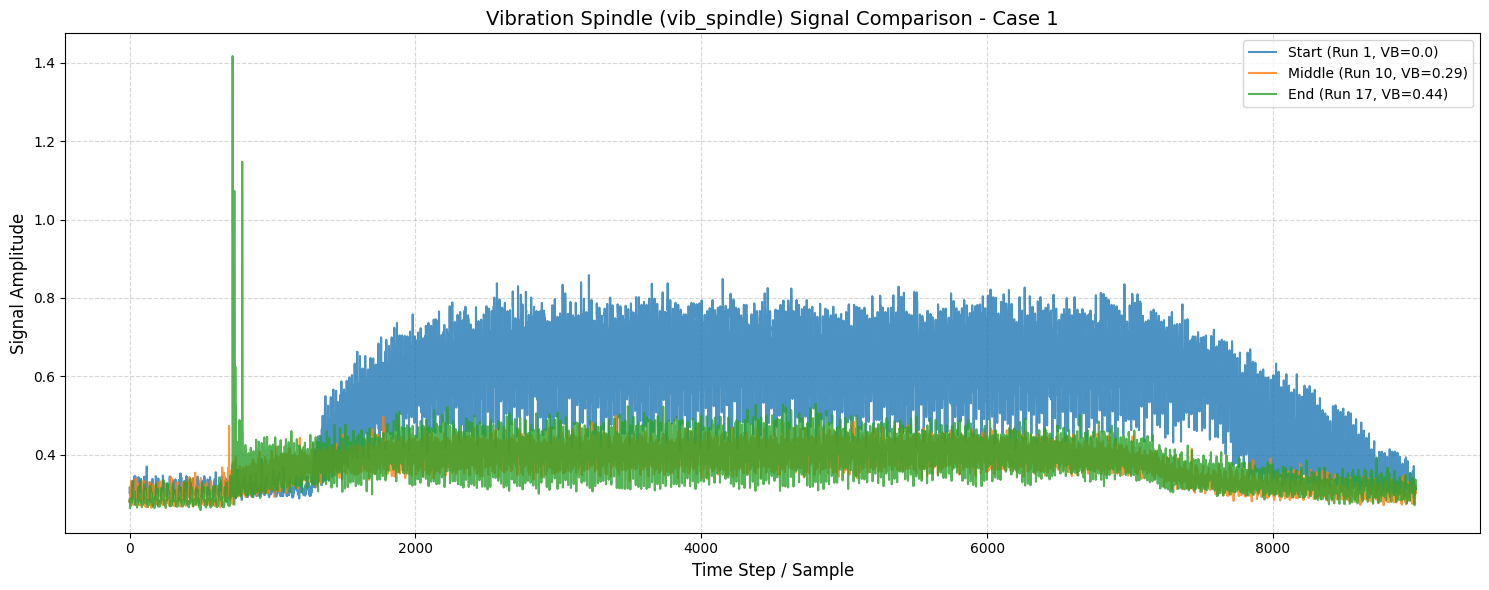

In [14]:
import matplotlib.pyplot as plt
import numpy as np

# Filter for Case 1
df_case1 = df_mill_filtered[df_mill_filtered['case'] == 1].sort_values(by='run')

# Get total number of runs in Case 1
num_runs = len(df_case1)

if num_runs >= 3:
    # Select the start, middle, and end runs
    start_idx = 0
    mid_idx = num_runs // 2
    end_idx = num_runs - 1

    start_row = df_case1.iloc[start_idx]
    mid_row = df_case1.iloc[mid_idx]
    end_row = df_case1.iloc[end_idx]

    # Plotting
    plt.figure(figsize=(15, 6))

    plt.plot(start_row['vib_spindle'], label=f"Start (Run {start_row['run']}, VB={start_row['VB']})", alpha=0.8)
    plt.plot(mid_row['vib_spindle'], label=f"Middle (Run {mid_row['run']}, VB={mid_row['VB']})", alpha=0.8)
    plt.plot(end_row['vib_spindle'], label=f"End (Run {end_row['run']}, VB={end_row['VB']})", alpha=0.8)

    plt.title("Vibration Spindle (vib_spindle) Signal Comparison - Case 1", fontsize=14)
    plt.xlabel("Time Step / Sample", fontsize=12)
    plt.ylabel("Signal Amplitude", fontsize=12)
    plt.legend(fontsize=10)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()
else:
    print(f"Not enough runs in Case 1 to plot start, middle, and end. Total runs: {num_runs}")

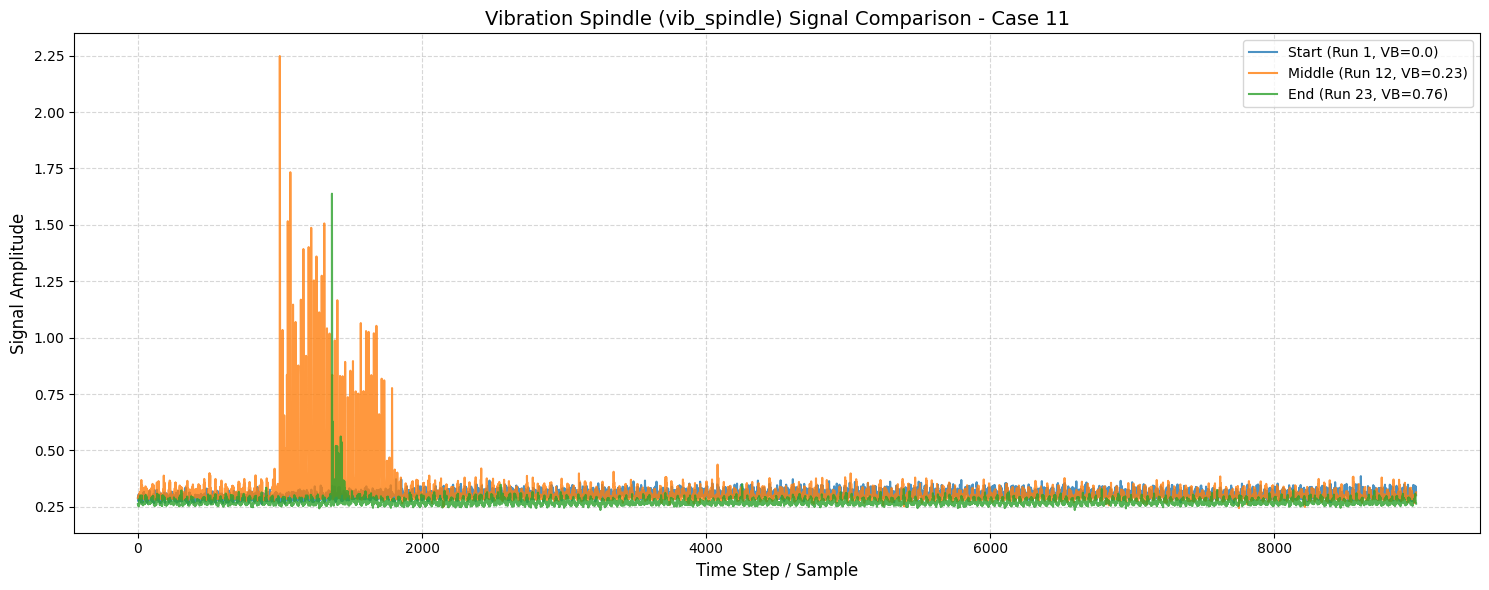

In [15]:
import matplotlib.pyplot as plt
import numpy as np

# Filter for Case 11
df_case11 = df_mill_filtered[df_mill_filtered['case'] == 11].sort_values(by='run')

# Get total number of runs in Case 11
num_runs_11 = len(df_case11)

if num_runs_11 >= 3:
    # Select the start, middle, and end runs
    start_idx = 0
    mid_idx = num_runs_11 // 2
    end_idx = num_runs_11 - 1

    start_row = df_case11.iloc[start_idx]
    mid_row = df_case11.iloc[mid_idx]
    end_row = df_case11.iloc[end_idx]

    # Plotting
    plt.figure(figsize=(15, 6))

    plt.plot(start_row['vib_spindle'], label=f"Start (Run {start_row['run']}, VB={start_row['VB']})", alpha=0.8)
    plt.plot(mid_row['vib_spindle'], label=f"Middle (Run {mid_row['run']}, VB={mid_row['VB']})", alpha=0.8)
    plt.plot(end_row['vib_spindle'], label=f"End (Run {end_row['run']}, VB={end_row['VB']})", alpha=0.8)

    plt.title("Vibration Spindle (vib_spindle) Signal Comparison - Case 11", fontsize=14)
    plt.xlabel("Time Step / Sample", fontsize=12)
    plt.ylabel("Signal Amplitude", fontsize=12)
    plt.legend(fontsize=10)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()
else:
    print(f"Not enough runs in Case 11 to plot start, middle, and end. Total runs: {num_runs_11}")

In [16]:
import numpy as np

def calculate_rms(signal_array):
    # Ensure the array is a numpy array of floats
    arr = np.array(signal_array, dtype=float)
    if len(arr) == 0:
        return 0.0
    return np.sqrt(np.mean(arr ** 2))

# Add the RMS columns to df_mill_filtered
df_mill_filtered['vib_spindle_rms'] = df_mill_filtered['vib_spindle'].apply(calculate_rms)
df_mill_filtered['vib_table_rms'] = df_mill_filtered['vib_table'].apply(calculate_rms)

# Display the updated columns along with case, run, and VB to verify
display(df_mill_filtered[['case', 'run', 'VB', 'vib_spindle_rms', 'vib_table_rms']].head())

,case,run,VB,vib_spindle_rms,vib_table_rms
0,1,1,0.00,0.570265,1.789685
3,1,4,0.11,0.523533,1.573666
5,1,6,0.20,0.469788,1.010552
6,1,7,0.24,0.405823,1.641365
7,1,8,0.29,0.414433,0.933600


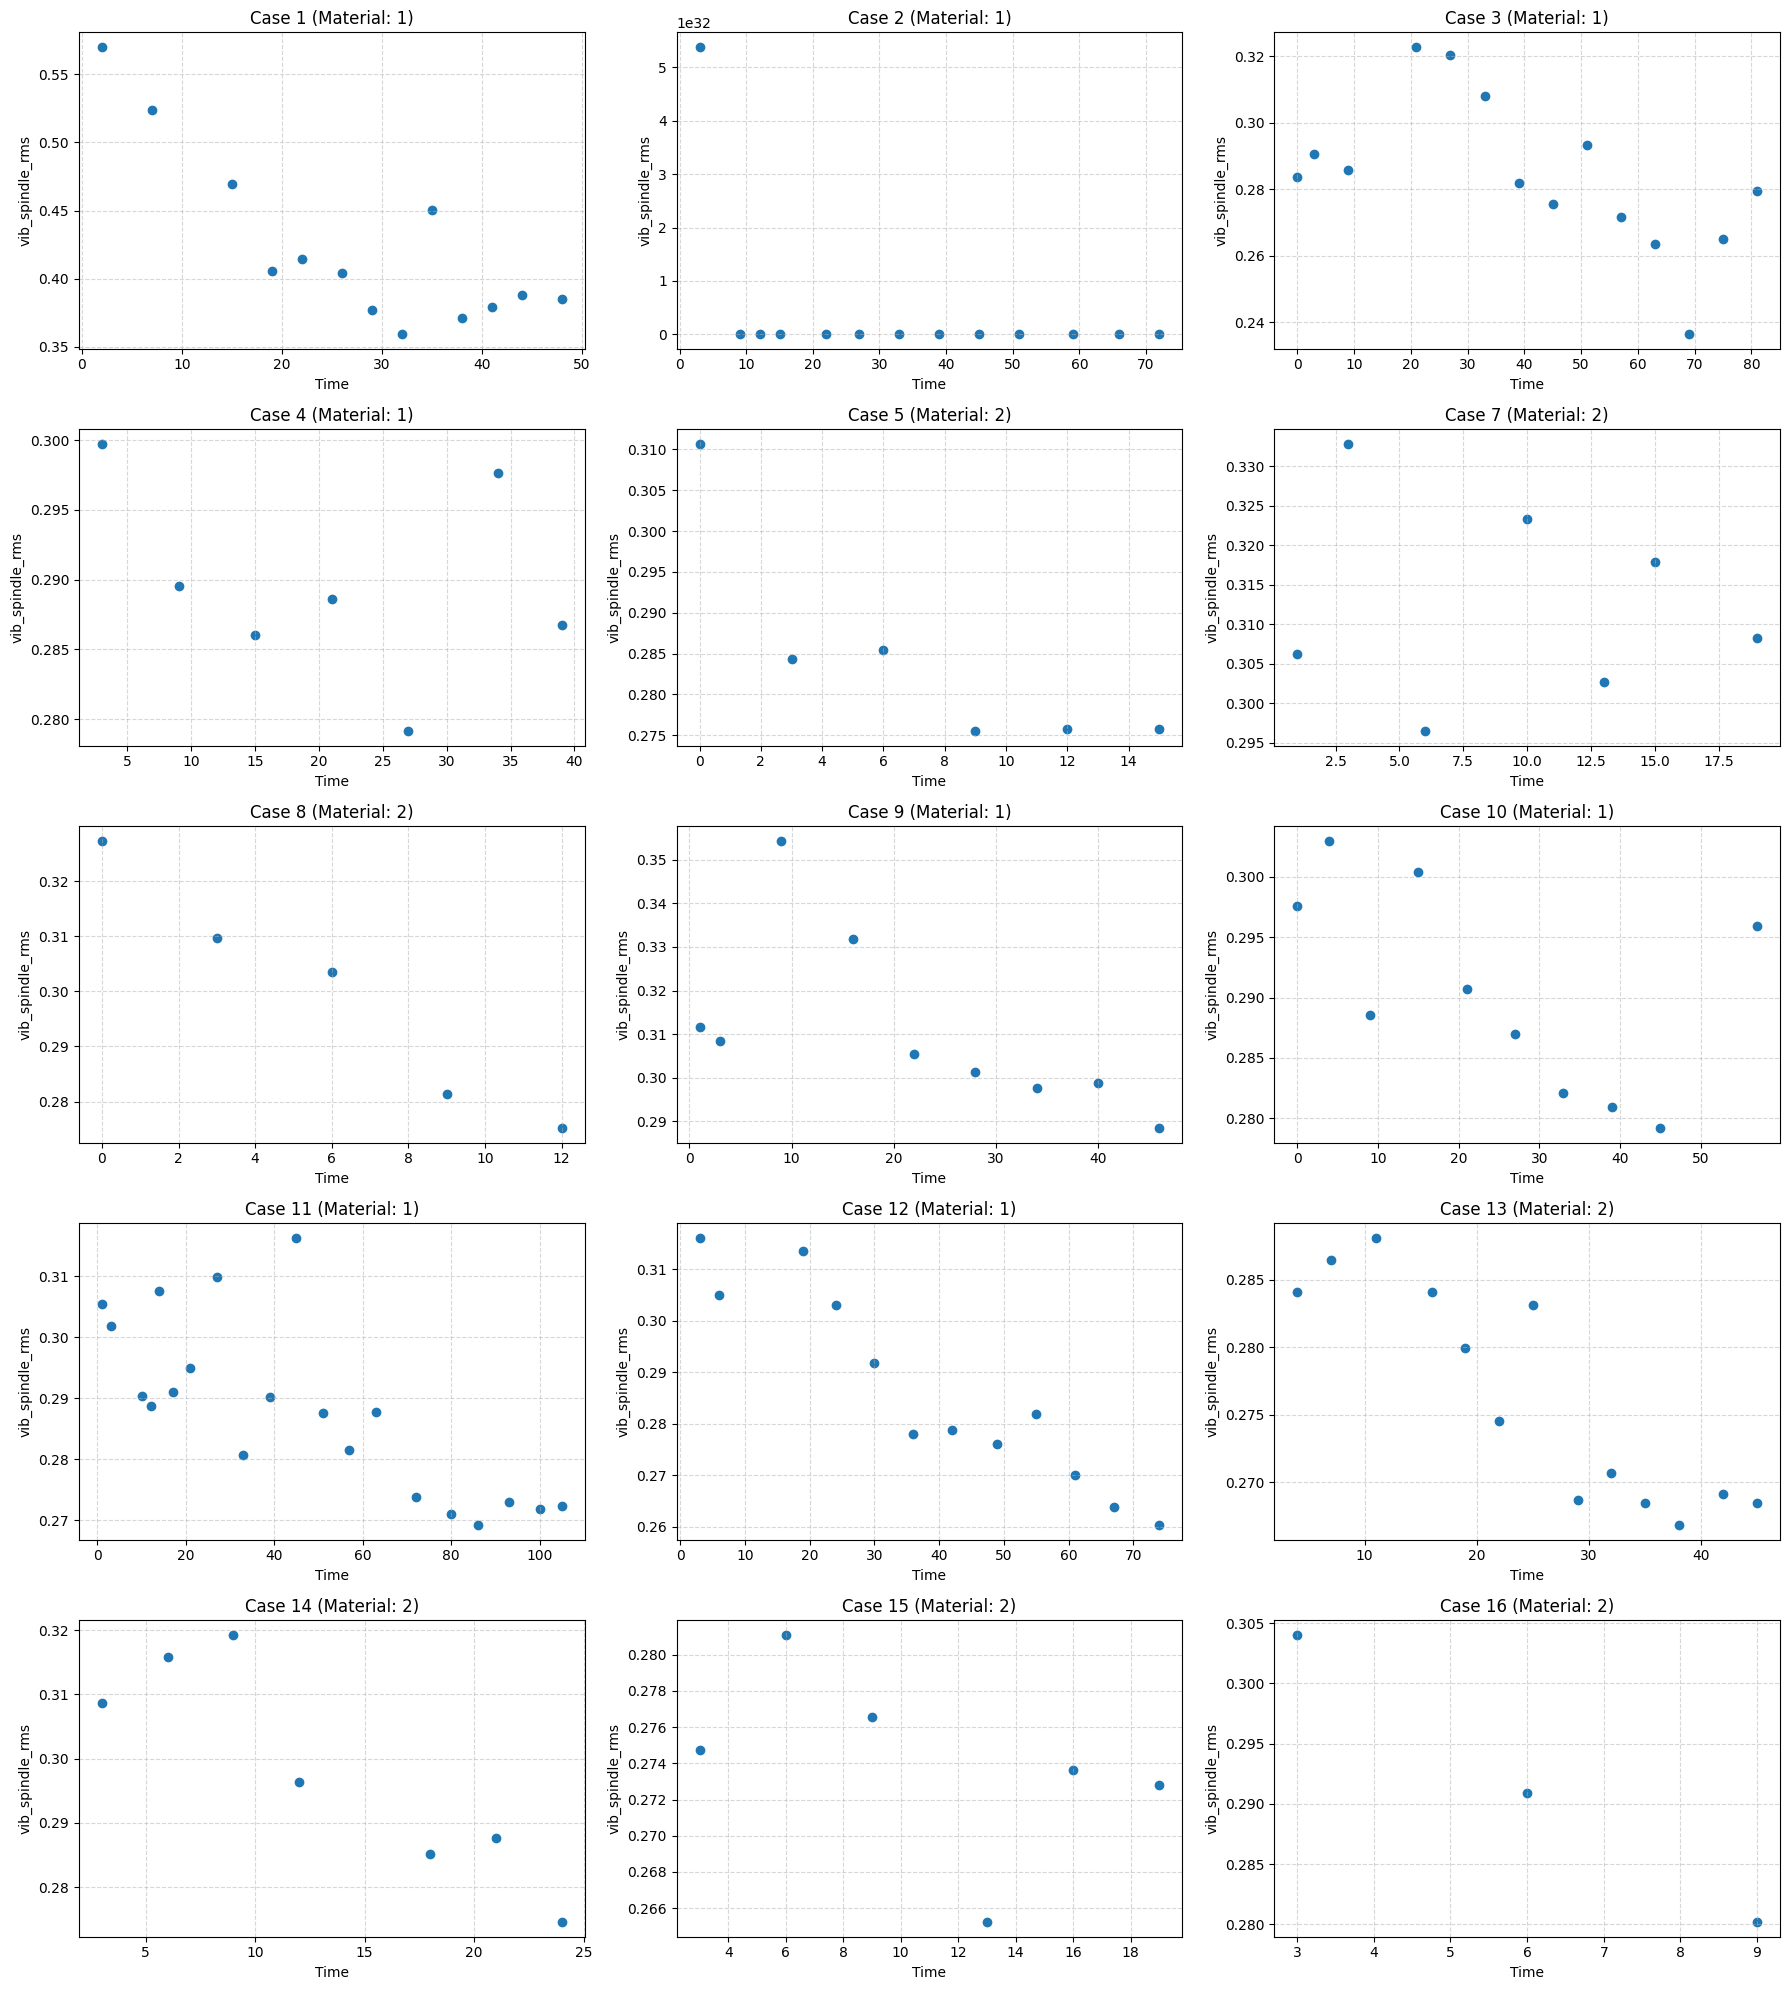

In [21]:
import matplotlib.pyplot as plt
import math

unique_cases = sorted(df_mill_filtered['case'].unique())
num_cases = len(unique_cases)

# We will arrange the separate plots in a grid of subplots
cols = 3
rows = math.ceil(num_cases / cols)

fig, axes = plt.subplots(rows, cols, figsize=(18, 4 * rows), sharex=False)
axes = axes.flatten()  # Flatten the 2D array of axes for easy indexing

for i, case_id in enumerate(unique_cases):
    case_df = df_mill_filtered[df_mill_filtered['case'] == case_id].sort_values(by='time')
    ax = axes[i]
    # Using ax.scatter to display points only (no connecting lines)
    ax.scatter(case_df['time'], case_df['vib_spindle_rms'], marker='o', color='C0')
    ax.set_title(f'Case {case_id} (Material: {case_df["material"].iloc[0]})')
    ax.set_xlabel('Time')
    ax.set_ylabel('vib_spindle_rms')
    ax.grid(True, linestyle='--', alpha=0.5)

# Hide any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [23]:
import pandas as pd

# Group by 'case' to find the maximum time reached in each case
max_time_per_case = df_mill_filtered.groupby('case')['time'].transform('max')

# Create a boolean mask where True means the row is within the first 75% of that case's final time
train_mask = df_mill_filtered['time'] <= 0.75 * max_time_per_case

# Split into training and validation datasets
df_train = df_mill_filtered[train_mask].copy()
df_val = df_mill_filtered[~train_mask].copy()

# Verify the split counts
print(f"Total rows in filtered data: {len(df_mill_filtered)}")
print(f"Training rows: {len(df_train)} ({len(df_train)/len(df_mill_filtered)*100:.1f}%)")
print(f"Validation rows: {len(df_val)} ({len(df_val)/len(df_mill_filtered)*100:.1f}%)")

# Display an example of the split for Case 1
print("\n--- Verification for Case 1 ---")
case1_all = df_mill_filtered[df_mill_filtered['case'] == 1].sort_values(by='time')
case1_train = df_train[df_train['case'] == 1].sort_values(by='time')
case1_val = df_val[df_val['case'] == 1].sort_values(by='time')

print(f"Case 1 max time: {case1_all['time'].max()}")
print(f"Case 1 training times: {case1_train['time'].tolist()}")
print(f"Case 1 validation times: {case1_val['time'].tolist()}")

Total rows in filtered data: 145
Training rows: 106 (73.1%)
Validation rows: 39 (26.9%)

--- Verification for Case 1 ---
Case 1 max time: 48
Case 1 training times: [2, 7, 15, 19, 22, 26, 29, 32, 35]
Case 1 validation times: [38, 41, 44, 48]


In [24]:
df_train.info()


<class 'pandas.core.frame.DataFrame'>
Index: 106 entries, 0 to 165
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   case             106 non-null    int64  
 1   run              106 non-null    int64  
 2   VB               106 non-null    float64
 3   time             106 non-null    int64  
 4   DOC              106 non-null    float64
 5   feed             106 non-null    float64
 6   material         106 non-null    int64  
 7   smcAC            106 non-null    object 
 8   smcDC            106 non-null    object 
 9   vib_table        106 non-null    object 
 10  vib_spindle      106 non-null    object 
 11  AE_table         106 non-null    object 
 12  AE_spindle       106 non-null    object 
 13  vib_spindle_rms  106 non-null    float64
 14  vib_table_rms    106 non-null    float64
dtypes: float64(5), int64(4), object(6)
memory usage: 13.2+ KB


In [25]:
df_val.info()

<class 'pandas.core.frame.DataFrame'>
Index: 39 entries, 12 to 166
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   case             39 non-null     int64  
 1   run              39 non-null     int64  
 2   VB               39 non-null     float64
 3   time             39 non-null     int64  
 4   DOC              39 non-null     float64
 5   feed             39 non-null     float64
 6   material         39 non-null     int64  
 7   smcAC            39 non-null     object 
 8   smcDC            39 non-null     object 
 9   vib_table        39 non-null     object 
 10  vib_spindle      39 non-null     object 
 11  AE_table         39 non-null     object 
 12  AE_spindle       39 non-null     object 
 13  vib_spindle_rms  39 non-null     float64
 14  vib_table_rms    39 non-null     float64
dtypes: float64(5), int64(4), object(6)
memory usage: 4.9+ KB


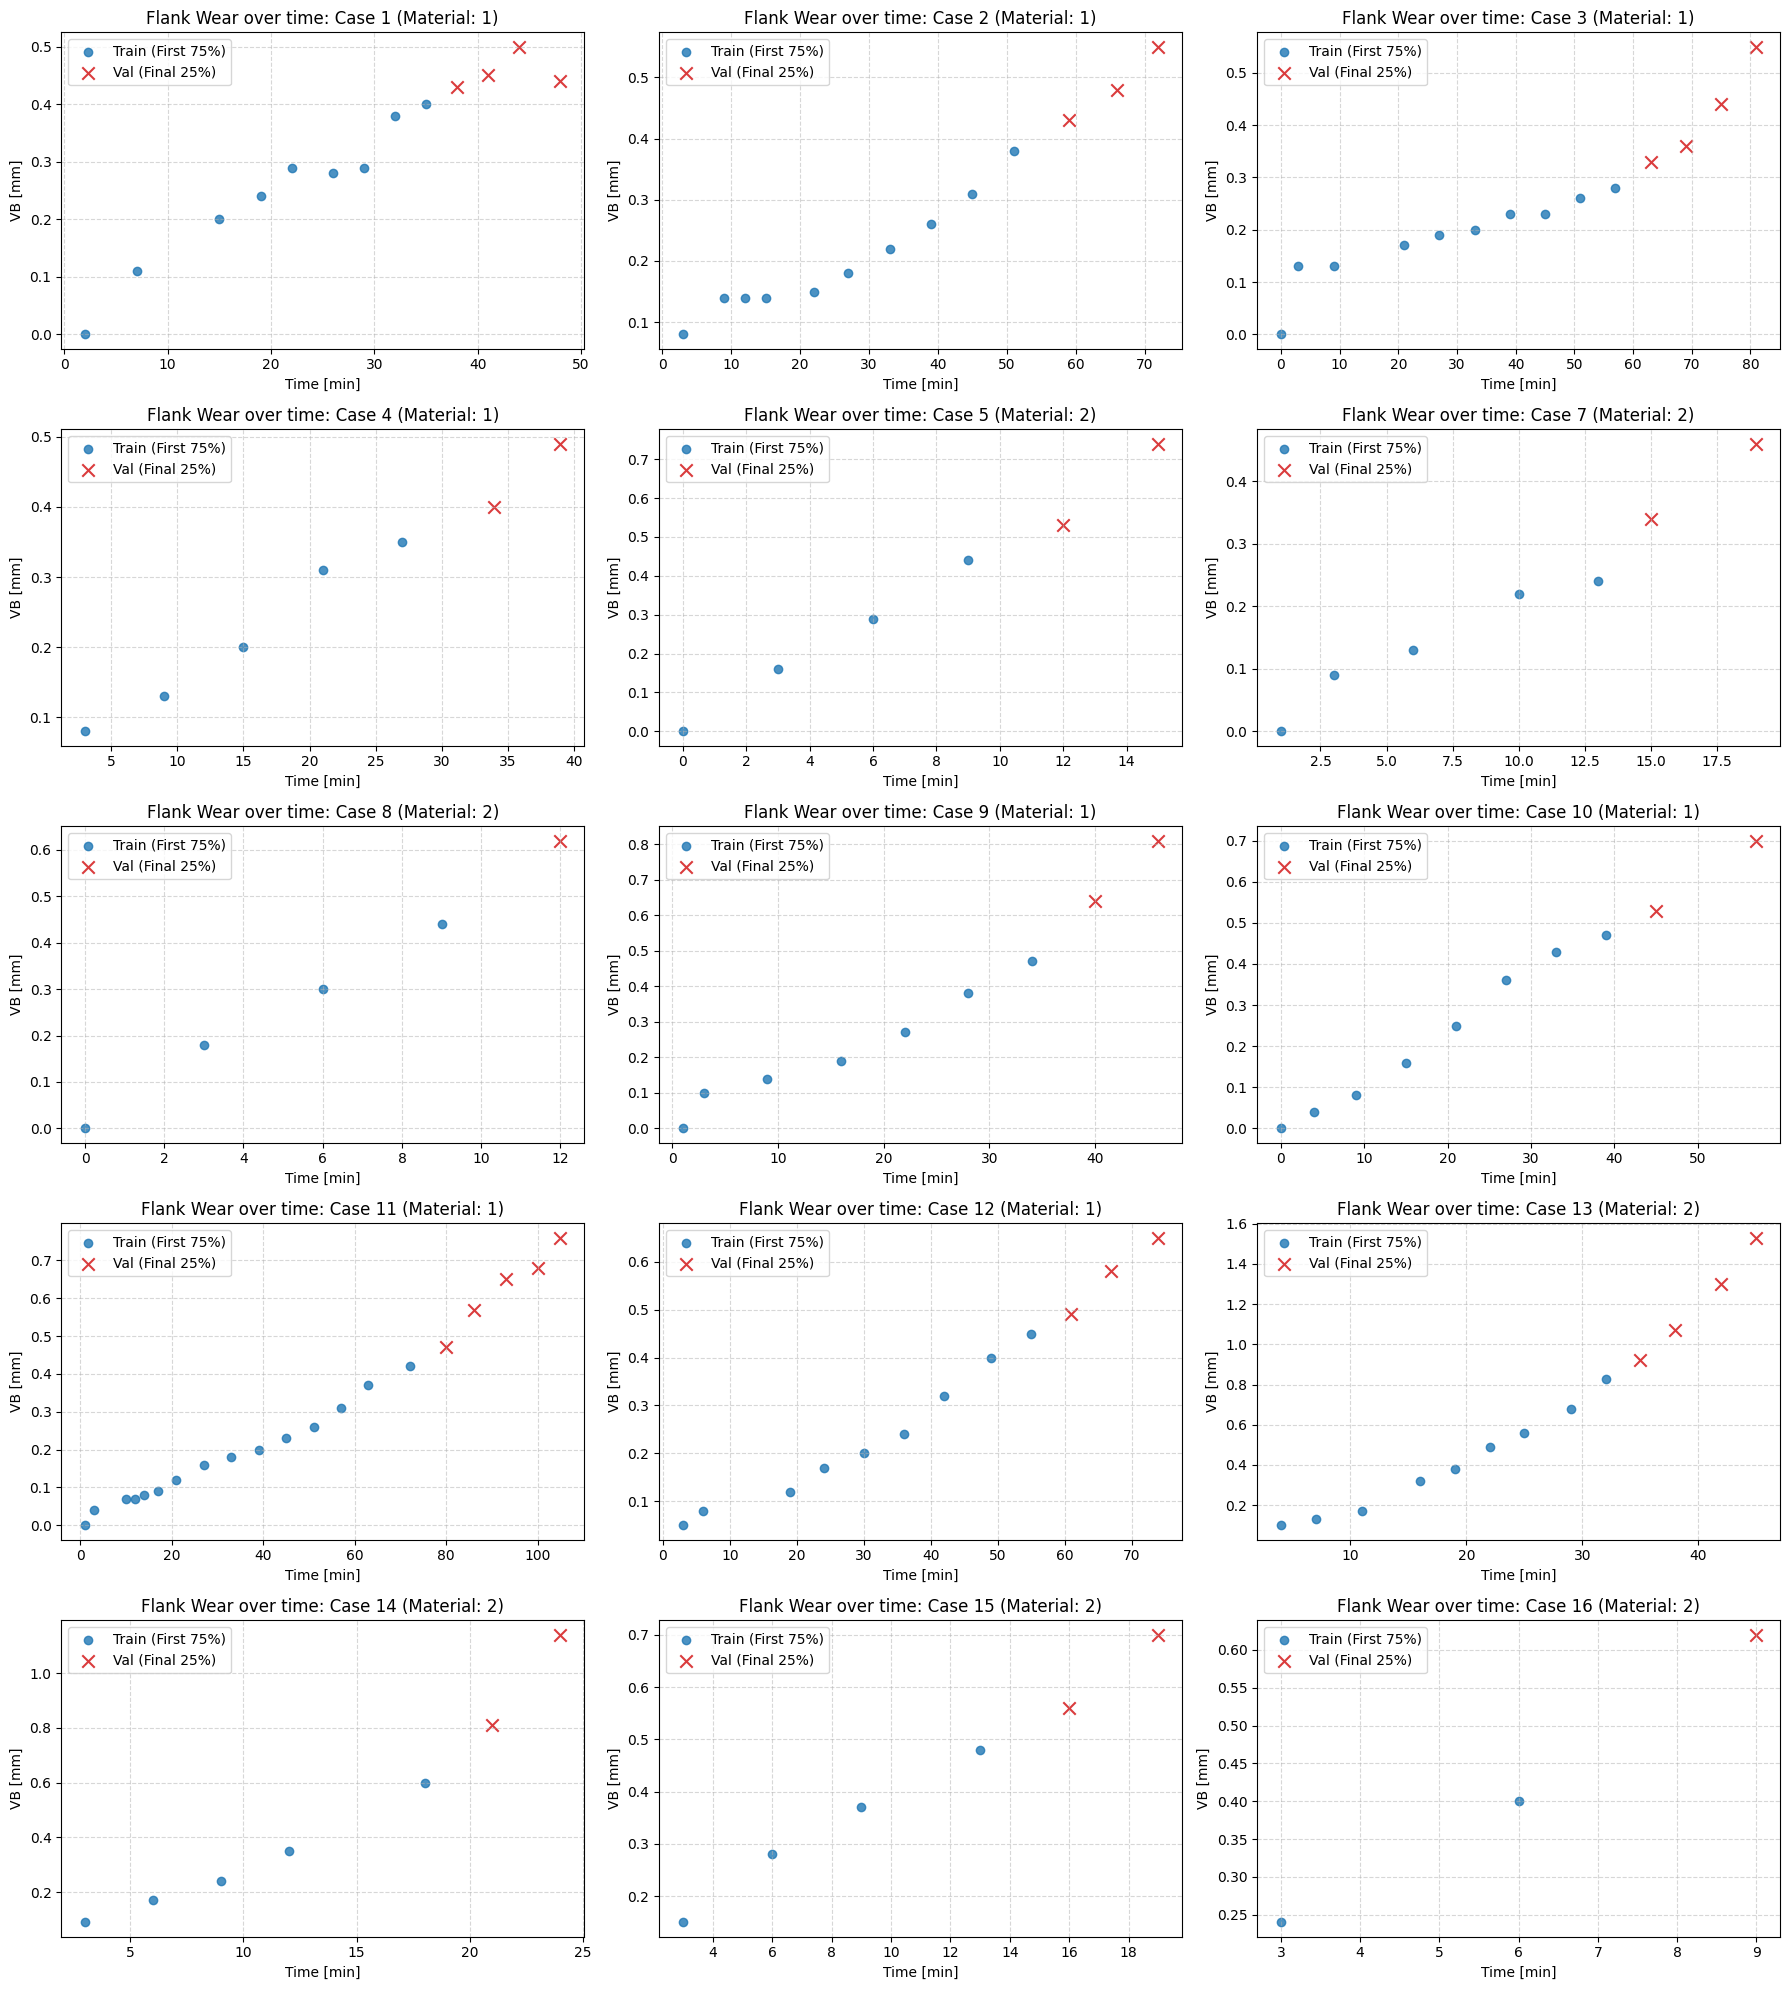

In [29]:
import matplotlib.pyplot as plt
import math

unique_cases = sorted(df_mill_filtered['case'].unique())
num_cases = len(unique_cases)

cols = 3
rows = math.ceil(num_cases / cols)

fig, axes = plt.subplots(rows, cols, figsize=(18, 4 * rows), sharex=False)
axes = axes.flatten()

for i, case_id in enumerate(unique_cases):
    # Extract training and validation sets for the current case
    case_train = df_train[df_train['case'] == case_id].sort_values(by='time')
    case_val = df_val[df_val['case'] == case_id].sort_values(by='time')

    ax = axes[i]

    # Scatter plot training points in blue
    ax.scatter(case_train['time'], case_train['VB'], color='tab:blue', label='Train (First 75%)', marker='o', alpha=0.8)

    # Scatter plot validation points in red
    ax.scatter(case_val['time'], case_val['VB'], color='tab:red', label='Val (Final 25%)', marker='x', s=80, alpha=0.9)

    # Labeling and styling
    ax.set_title(f'Flank Wear over time: Case {case_id} (Material: {df_mill_filtered[df_mill_filtered["case"] == case_id]["material"].iloc[0]})')
    ax.set_xlabel('Time [min]')
    ax.set_ylabel('VB [mm]')
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend()

# Hide unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()